# Dijital Sinyal İşleme ile Sinyal Sınıflandırma — Adım Adım Uygulama

Bu notebook'ta bir sinyali **ham hâlinden başlayıp bir makine öğrenmesi modeliyle sınıflandırmaya** kadar götüreceğiz.

### Hikâyemiz
Bir fabrikada bir motorun üzerine **titreşim sensörü** takıldığını düşünelim. Motor üç farklı hızda çalışabiliyor:

| Sınıf | Çalışma durumu | Titreşimin baskın frekansı |
|---|---|---|
| 0 | Düşük hız | yaklaşık 3 – 9 Hz |
| 1 | Orta hız | yaklaşık 8 – 14 Hz |
| 2 | Yüksek hız | yaklaşık 13 – 20 Hz |

Amacımız: **Sadece titreşim sinyaline bakarak motorun hangi hızda çalıştığını otomatik olarak bulmak.**

> Not: Gerçek bir sensörümüz olmadığı için sinyalleri bilgisayarda **yapay olarak (sentetik)** üreteceğiz. Ama gerçek hayattaki sorunları (gürültü, şebeke paraziti, kayma) da ekleyeceğiz.

### İzleyeceğimiz yol (iş akışı)

```
1. Sinyali tanı      →  2. Ön işleme       →  3. Filtreleme
(ham sinyal)            (DC/kayma silme)       (gürültü temizleme)
        ↓
4. Öznitelik çıkarma →  5. Eğitim/Test ayırma →  6. Sınıflandırma  →  7. Yorumlama
(sinyalden sayılar)     (veriyi ikiye böl)       (k-NN modeli)         (sonuçlar ne diyor?)
```

Her kod hücresinden önce o hücrenin **ne yaptığını** ve **neden yaptığını** açıklayan bir metin bulacaksınız. Hücreleri yukarıdan aşağıya sırayla çalıştırın (`Shift + Enter`).

## 0. Kütüphaneleri Yükleme

Python'da her işi sıfırdan yazmayız; hazır **kütüphaneler** kullanırız:

- **numpy** → Sayısal hesaplamalar ve diziler (sinyalimiz aslında bir sayı dizisidir).
- **matplotlib** → Grafik çizmek.
- **scipy.signal** → Filtre tasarlamak ve uygulamak gibi sinyal işleme araçları.
- **pandas** → Verileri tablo hâlinde tutmak (Excel tablosu gibi).
- **scikit-learn (sklearn)** → Makine öğrenmesi: veri ayırma, ölçekleme, sınıflandırıcı ve başarı ölçümü.

`np.random.default_rng(42)` satırı rastgele sayı üretecini sabitler. Böylece notebook'u her çalıştırdığınızda **aynı sonuçları** alırsınız (tekrarlanabilirlik).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# Rastgele sayı üreteci: 42 "tohum" değeri sayesinde sonuçlar hep aynı çıkar
rng = np.random.default_rng(42)

# Grafiklerin varsayılan boyutu
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["axes.grid"] = True

print("Kütüphaneler başarıyla yüklendi.")

Kütüphaneler başarıyla yüklendi.


## 1. Sinyali Tanıyalım

### 1.1 Temel kavramlar
- **Örnekleme frekansı (fs):** Sensörün saniyede kaç ölçüm aldığı. Biz `fs = 200 Hz` seçiyoruz → saniyede 200 ölçüm.
- **Süre:** Her kayıt 2 saniye uzunluğunda olacak → her sinyal `200 × 2 = 400` sayıdan oluşur.
- **Nyquist frekansı:** Örnekleme frekansının yarısı (`fs/2 = 100 Hz`). Bu sistemle en fazla 100 Hz'e kadar olan frekansları doğru görebiliriz.

### 1.2 Sinyal üreten fonksiyon
Aşağıdaki fonksiyon tek bir "sensör kaydı" üretir. Kayıt şu parçaların **toplamıdır**:

| Parça | Ne anlama geliyor? | İstiyor muyuz? |
|---|---|---|
| Ana sinüs (3–20 Hz) | Motorun asıl titreşimi — **bilgi bunun içinde** | ✅ Evet |
| İkinci harmonik (2×f) | Gerçek motorlarda görülen ek titreşim | ✅ Evet |
| DC ofset (sabit değer) | Sensörün sıfır noktasının kayması | ❌ Hayır |
| Doğrusal kayma (trend) | Sensörün zamanla ısınıp kayması | ❌ Hayır |
| 50 Hz parazit | Elektrik şebekesinden gelen gürültü | ❌ Hayır |
| Beyaz gürültü | Rastgele ölçüm hatası | ❌ Hayır |

İstemediğimiz parçaları sonraki adımlarda **ön işleme** ve **filtreleme** ile temizleyeceğiz.

In [2]:
fs = 200                 # Örnekleme frekansı (Hz)
sure = 2.0               # Her kaydın süresi (saniye)
t = np.arange(0, sure, 1/fs)   # Zaman ekseni: 0, 0.005, 0.010, ... 1.995 saniye
N = len(t)               # Bir sinyaldeki örnek sayısı

# Her sınıf için baskın frekansın seçileceği aralık (Hz)
frekans_araliklari = {0: (3, 9), 1: (8, 14), 2: (13, 20)}
sinif_adlari = {0: "Düşük hız", 1: "Orta hız", 2: "Yüksek hız"}

def sinyal_uret(sinif):
    # Verilen sınıfa ait tek bir gürültülü sensör kaydı üretir.
    f_min, f_max = frekans_araliklari[sinif]
    f = rng.uniform(f_min, f_max)          # Bu kayda özel baskın frekans
    A = rng.uniform(0.5, 1.5)              # Genlik (her sınıfta benzer aralıkta!)

    ana_sinyal = A * np.sin(2*np.pi*f*t)                      # Asıl titreşim
    harmonik   = 0.3*A * np.sin(2*np.pi*2*f*t)                # 2. harmonik
    dc_ofset   = rng.uniform(-2, 2)                           # Sabit kayma
    trend      = rng.uniform(-1, 1) * t                       # Zamanla artan kayma
    sebeke     = 0.8 * np.sin(2*np.pi*50*t)                   # 50 Hz şebeke paraziti
    gurultu    = 0.5 * rng.standard_normal(N)                 # Beyaz gürültü

    return ana_sinyal + harmonik + dc_ofset + trend + sebeke + gurultu, f

# Örnek olarak "Orta hız" sınıfından bir sinyal üretelim
ornek_sinyal, ornek_f = sinyal_uret(sinif=1)

print(f"Sinyaldeki örnek sayısı : {N}")
print(f"Bu kaydın gerçek frekansı: {ornek_f:.2f} Hz")

Sinyaldeki örnek sayısı : 400
Bu kaydın gerçek frekansı: 12.64 Hz


### 1.3 Ham sinyali çizelim (zaman domeni)
**Zaman domeni**, sinyalin değerinin zamanla nasıl değiştiğini gösterir. Aşağıdaki grafiğe bakınca sinyalin

- sıfırın etrafında değil, yukarıda/aşağıda bir yerde durduğunu (**DC ofset**),
- zamanla yukarı ya da aşağı kaydığını (**trend**),
- çok "tırtıklı" olduğunu (**gürültü**)

görebilirsiniz. Asıl titreşimi gözle seçmek zor!

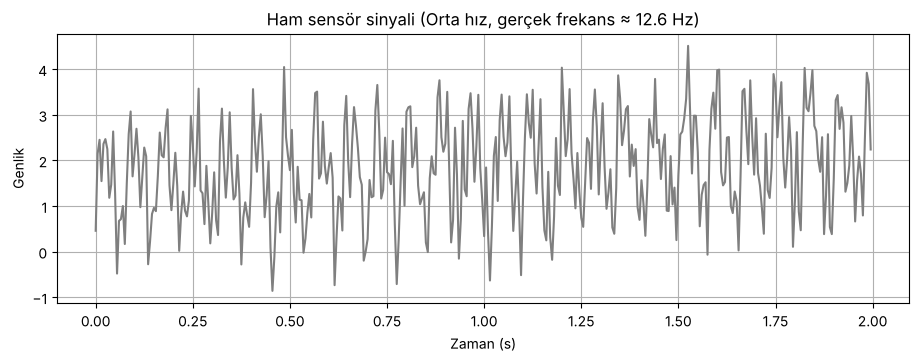

In [3]:
plt.plot(t, ornek_sinyal, color="tab:gray")
plt.title(f"Ham sensör sinyali (Orta hız, gerçek frekans ≈ {ornek_f:.1f} Hz)")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.show()

### 1.4 Frekans domeni: FFT ile sinyalin "içine" bakmak
**Fourier Dönüşümü (FFT)**, bir sinyalin hangi frekanslardan oluştuğunu gösterir. Bir şarkıdaki notaları ayırt etmek gibi düşünebilirsiniz.

Aşağıda bir **yardımcı fonksiyon** yazıyoruz; sinyalin genlik spektrumunu hesaplıyor. Sadece pozitif frekanslara bakmak yeterli olduğu için `np.fft.rfft` kullanıyoruz.

Grafikte dikkat edilecek noktalar:
- **0 Hz civarındaki yüksek değer** → DC ofset ve trend.
- **Motor frekansında bir tepe** → Asıl bilgimiz.
- **50 Hz'de keskin bir tepe** → Şebeke paraziti.
- Her yere yayılmış küçük değerler → Beyaz gürültü.

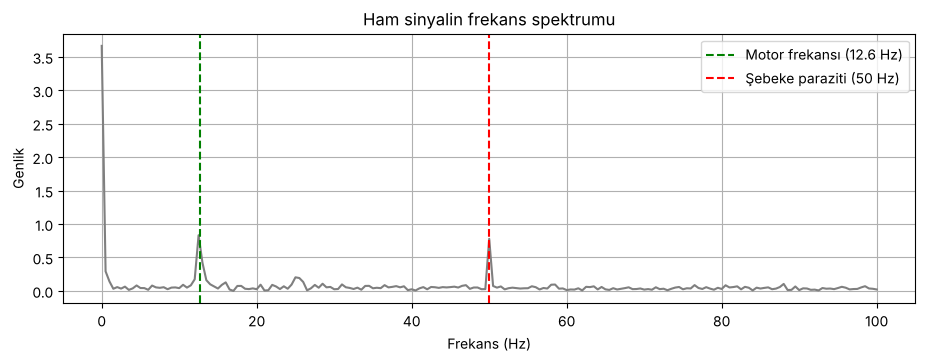

In [4]:
def spektrum_hesapla(x, fs):
    # Sinyalin frekans eksenini ve genlik spektrumunu döndürür.
    X = np.fft.rfft(x)                      # Hızlı Fourier Dönüşümü
    frekanslar = np.fft.rfftfreq(len(x), 1/fs)
    genlik = np.abs(X) / len(x) * 2         # Genliği ölçeklendir
    return frekanslar, genlik

frek, genlik = spektrum_hesapla(ornek_sinyal, fs)

plt.plot(frek, genlik, color="tab:gray")
plt.axvline(ornek_f, color="green", linestyle="--", label=f"Motor frekansı ({ornek_f:.1f} Hz)")
plt.axvline(50, color="red", linestyle="--", label="Şebeke paraziti (50 Hz)")
plt.title("Ham sinyalin frekans spektrumu")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Genlik")
plt.legend()
plt.show()

## 2. Ön İşleme (Preprocessing)

Ön işleme, sinyali analiz etmeye **hazır hâle getirmektir**. Bölüm 1.3'teki grafikte ham sinyalde iki sorun görmüştük:

| Sorun | Grafikte nasıl görünüyor? | Nasıl düzelteceğiz? |
|---|---|---|
| **DC ofset** | Sinyal sıfırın etrafında değil, yukarıda ya da aşağıda bir seviyede salınıyor | Sinyalin **ortalamasını** çıkararak |
| **Doğrusal trend** | Sinyal zamanla yavaş yavaş yukarı ya da aşağı kayıyor | Sinyale **en iyi uyan düz çizgiyi** bulup çıkararak |

Bu iki işlemi önce **elle, adım adım** yapacağız ve her adımın sonucunu göreceğiz. Sonra aynı işi tek satırda yapan hazır `signal.detrend` fonksiyonunu kullanacağız.

> **Normalizasyon hakkında:** Bazı uygulamalarda sinyal ayrıca [-1, 1] aralığına ölçeklenir. Biz bunu burada **yapmıyoruz**, çünkü genlik bilgisini öznitelik olarak kullanmak istiyoruz. Ölçeklemeyi daha sonra özniteliklere uygulayacağız (Bölüm 6.1).

### 2.1 Adım 1 — DC ofseti kaldırmak (ortalamayı çıkarmak)
**DC ofset**, sinyale eklenmiş sabit bir değerdir. Örneğin sensörün sıfır noktası +1.5'e kaymışsa her ölçüm 1.5 fazla çıkar.

Çözüm çok basit: Sinyalin ortalamasını hesaplayıp her değerden çıkarırız:

$$x_{DC\ yok}[n] = x[n] - \text{ortalama}(x)$$

Bu işlemden sonra sinyalin ortalaması **tam olarak 0** olur.

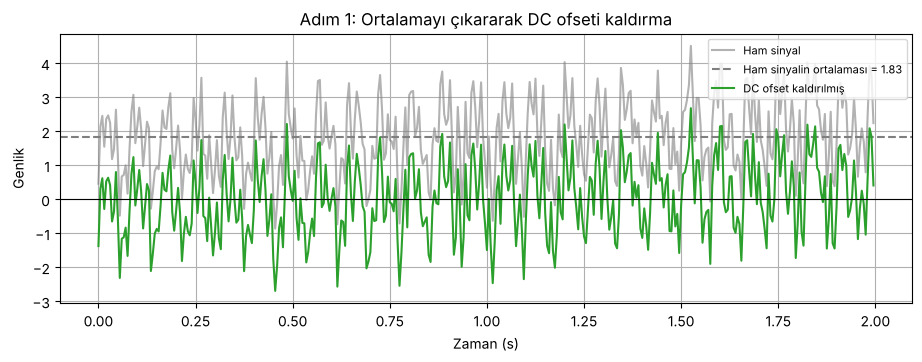

Ham sinyalin ortalaması          : 1.833
DC kaldırılmış sinyalin ortalaması: 0.000


In [5]:
# Ham sinyalin ortalamasını hesapla (DC ofsetin tahmini)
ortalama = np.mean(ornek_sinyal)

# Ortalamayı her değerden çıkar
dc_kaldirilmis = ornek_sinyal - ortalama

plt.plot(t, ornek_sinyal, color="tab:gray", alpha=0.6, label="Ham sinyal")
plt.axhline(ortalama, color="tab:gray", linestyle="--", label=f"Ham sinyalin ortalaması = {ortalama:.2f}")
plt.plot(t, dc_kaldirilmis, color="tab:green", label="DC ofset kaldırılmış")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Adım 1: Ortalamayı çıkararak DC ofseti kaldırma")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.legend(loc="upper right", fontsize=8)
plt.show()

print(f"Ham sinyalin ortalaması          : {ornek_sinyal.mean():.3f}")
print(f"DC kaldırılmış sinyalin ortalaması: {dc_kaldirilmis.mean():.3f}")

Yeşil sinyal artık sıfırın etrafında. **Ama dikkat:** Sinyal hâlâ zamanla eğimli bir şekilde kayıyor olabilir (başında aşağıda, sonunda yukarıda ya da tersi). Ortalamayı çıkarmak bu **eğimi** düzeltmez. Bunun için ikinci adıma ihtiyacımız var.

### 2.2 Adım 2 — Doğrusal trendi bulmak ve kaldırmak
**Trend**, sinyalin zamanla yavaşça artması veya azalmasıdır (örneğin sensör ısındıkça ölçümün kayması). Doğrusal trendi bir **doğru denklemi** ile ifade edebiliriz:

$$\text{trend}(t) = a \cdot t + b \qquad (a = \text{eğim},\ b = \text{kesişim})$$

`np.polyfit(t, x, 1)` fonksiyonu, sinyalin içinden geçen **en iyi düz çizgiyi** bulur (en küçük kareler yöntemi) ve bize `a` ile `b` değerlerini verir. Ardından bu çizgiyi sinyalden çıkarırız.

> Sinyalin içindeki titreşim yukarı-aşağı simetrik olduğu için çizgiyi pek etkilemez; çizgi sadece sinyalin "genel gidişatını" yakalar.

Bulunan trend çizgisi: trend(t) = 0.408 · t + (-0.407)
Yani sinyal her saniyede yaklaşık 0.408 birim kayıyor.


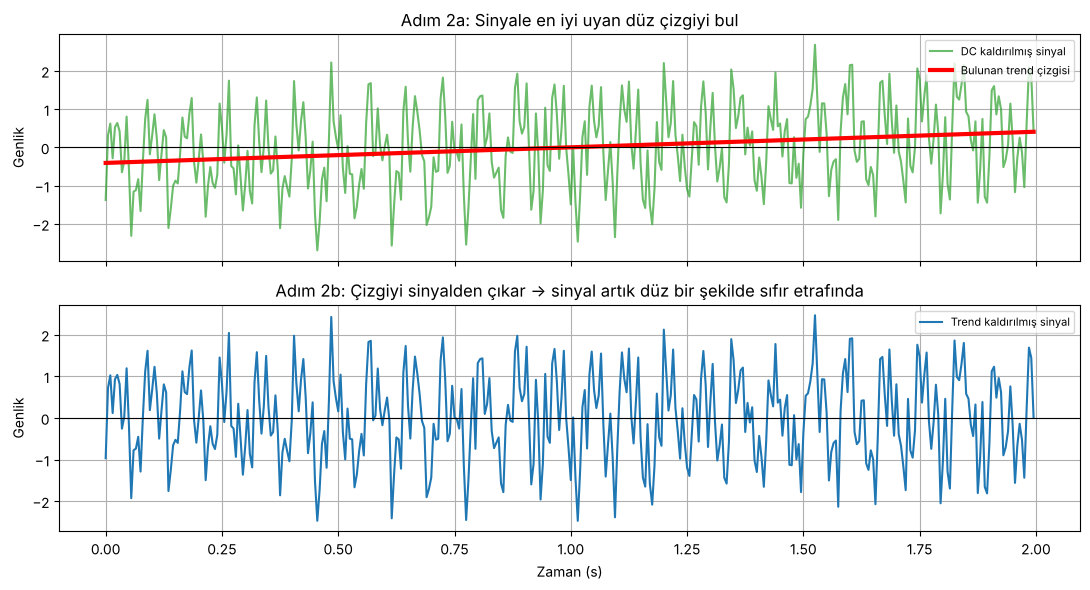

In [6]:
# 1. derece polinom (düz çizgi) uydur: trend = a*t + b
a, b_kesisim = np.polyfit(t, dc_kaldirilmis, deg=1)
trend_cizgisi = a * t + b_kesisim

print(f"Bulunan trend çizgisi: trend(t) = {a:.3f} · t + ({b_kesisim:.3f})")
print(f"Yani sinyal her saniyede yaklaşık {a:.3f} birim kayıyor.")

# Trend çizgisini sinyalden çıkar
trend_kaldirilmis = dc_kaldirilmis - trend_cizgisi

fig, eksen = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Üst grafik: Sinyal ve bulunan trend çizgisi
eksen[0].plot(t, dc_kaldirilmis, color="tab:green", alpha=0.7, label="DC kaldırılmış sinyal")
eksen[0].plot(t, trend_cizgisi, color="red", linewidth=3, label="Bulunan trend çizgisi")
eksen[0].axhline(0, color="black", linewidth=0.8)
eksen[0].set_title("Adım 2a: Sinyale en iyi uyan düz çizgiyi bul")
eksen[0].set_ylabel("Genlik")
eksen[0].legend(loc="upper right", fontsize=8)

# Alt grafik: Trend çıkarıldıktan sonra
eksen[1].plot(t, trend_kaldirilmis, color="tab:blue", label="Trend kaldırılmış sinyal")
eksen[1].axhline(0, color="black", linewidth=0.8)
eksen[1].set_title("Adım 2b: Çizgiyi sinyalden çıkar → sinyal artık düz bir şekilde sıfır etrafında")
eksen[1].set_xlabel("Zaman (s)")
eksen[1].set_ylabel("Genlik")
eksen[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

### 2.3 Hazır fonksiyon: `signal.detrend`
Yukarıda iki adımda elle yaptığımız işin aynısını `scipy` kütüphanesindeki `signal.detrend(x, type="linear")` fonksiyonu **tek satırda** yapar.

Bunu kanıtlayalım: İki sonucu `np.allclose` ile karşılaştırıyoruz. Bu fonksiyon iki dizinin (çok küçük yuvarlama farkları dışında) aynı olup olmadığını söyler.

Bundan sonra notebook'un geri kalanında ön işleme için `on_isleme()` fonksiyonunu kullanacağız.

In [7]:
def on_isleme(x):
    # DC ofset ve doğrusal trendi kaldırır (Adım 1 + Adım 2'nin kısa yolu).
    return signal.detrend(x, type="linear")

on_islenmis = on_isleme(ornek_sinyal)

ayni_mi = np.allclose(on_islenmis, trend_kaldirilmis)
print(f"Elle yaptığımız sonuç ile signal.detrend sonucu aynı mı?  →  {ayni_mi}")

Elle yaptığımız sonuç ile signal.detrend sonucu aynı mı?  →  True


### 2.4 Ön işleme neden önemli? İki somut kanıt

Ön işleme "grafik güzel görünsün" diye yapılmaz; sonraki adımları **doğrudan etkiler**.

**Kanıt 1 — Frekans spektrumu:** DC ofset ve trend, spektrumun **0 Hz civarında** çok büyük bir tepe oluşturur. Bu tepe, asıl ilgilendiğimiz motor frekansını gölgede bırakabilir. Hatta "baskın frekansı" bulmaya çalışırsak yanlışlıkla 0 Hz'i bulabiliriz!

**Kanıt 2 — Sıfır geçiş sayısı:** İleride (Bölüm 5) "sinyal kaç kez sıfır çizgisini kesiyor?" sorusunu bir öznitelik olarak kullanacağız. Sinyal yukarı kaymışsa sıfır çizgisini **hiç kesmeyebilir** ve bu öznitelik tamamen yanlış çıkar.

Aşağıdaki kod bu iki etkiyi ham ve ön işlenmiş sinyal üzerinde karşılaştırıyor.

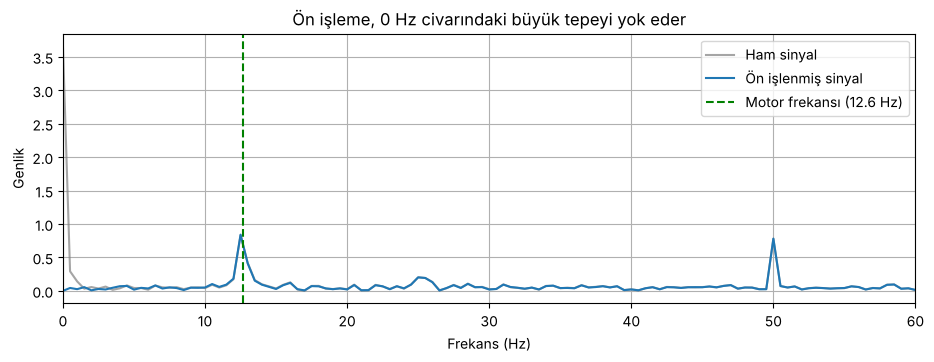

Spektrumdaki en büyük tepenin frekansı (baskın frekans):
  Ham sinyal        : 0.0 Hz
  Ön işlenmiş sinyal: 12.5 Hz   (gerçek motor frekansı: 12.6 Hz)

Sinyalin sıfır çizgisini kesme sayısı:
  Ham sinyal        : 28
  Ön işlenmiş sinyal: 135


In [8]:
# --- Kanıt 1: Spektrum karşılaştırması ---
f_ham, g_ham = spektrum_hesapla(ornek_sinyal, fs)
f_on, g_on = spektrum_hesapla(on_islenmis, fs)

plt.plot(f_ham, g_ham, color="tab:gray", alpha=0.7, label="Ham sinyal")
plt.plot(f_on, g_on, color="tab:blue", label="Ön işlenmiş sinyal")
plt.axvline(ornek_f, color="green", linestyle="--", label=f"Motor frekansı ({ornek_f:.1f} Hz)")
plt.xlim(0, 60)
plt.title("Ön işleme, 0 Hz civarındaki büyük tepeyi yok eder")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Genlik")
plt.legend()
plt.show()

print("Spektrumdaki en büyük tepenin frekansı (baskın frekans):")
print(f"  Ham sinyal        : {f_ham[np.argmax(g_ham)]:.1f} Hz")
print(f"  Ön işlenmiş sinyal: {f_on[np.argmax(g_on)]:.1f} Hz   (gerçek motor frekansı: {ornek_f:.1f} Hz)")

# --- Kanıt 2: Sıfır geçiş sayısı karşılaştırması ---
def sifir_gecis_say(x):
    # Sinyalin işaretinin (+/-) kaç kez değiştiğini sayar.
    return np.sum(np.diff(np.sign(x)) != 0)

print("\nSinyalin sıfır çizgisini kesme sayısı:")
print(f"  Ham sinyal        : {sifir_gecis_say(ornek_sinyal)}")
print(f"  Ön işlenmiş sinyal: {sifir_gecis_say(on_islenmis)}")

**Özet:** Ön işleme olmadan sinyalin en baskın frekansı **0 Hz** gibi görünüyor ve sıfır geçiş sayısı gerçeği yansıtmıyor. Ön işlemeden sonra spektrumdaki en büyük tepe motor frekansına denk geliyor ve sinyal sıfır çizgisini düzgün şekilde kesiyor.

Ancak sinyalde hâlâ **50 Hz parazit** ve **gürültü** var. Sıfır geçiş sayısı bu yüzden hâlâ olması gerekenden fazla. Bunları bir sonraki adımda **filtreleme** ile temizleyeceğiz.

## 3. Filtreleme

Sinyalde hâlâ **50 Hz parazit** ve **yüksek frekanslı gürültü** var. Bizim motor frekanslarımız en fazla ~20 Hz (harmonikle ~40 Hz) olduğuna göre, 30 Hz'in üstünü atmak bilgiyi büyük ölçüde korur, paraziti ise siler.

Bunun için bir **alçak geçiren filtre (low-pass filter)** kullanıyoruz:
- **Alçak geçiren filtre:** Kesim frekansının *altındaki* frekansları geçirir, *üstündekileri* zayıflatır.
- **Butterworth filtresi:** Geçirme bandında düz (dalgasız) bir cevabı olan, en yaygın filtre türlerinden biri.
- **Derece (order = 4):** Filtrenin ne kadar "keskin" kestiğini belirler. Derece arttıkça geçiş daha diktir.
- **`filtfilt`:** Filtreyi sinyale önce ileri, sonra geri uygular. Böylece sinyalde **zaman kayması (faz gecikmesi) oluşmaz**.

### 3.1 Filtreyi tasarlayalım ve frekans cevabını görelim
Frekans cevabı grafiği, filtrenin her frekansı ne kadar geçirdiğini gösterir (1 = tamamen geçirir, 0 = tamamen durdurur).

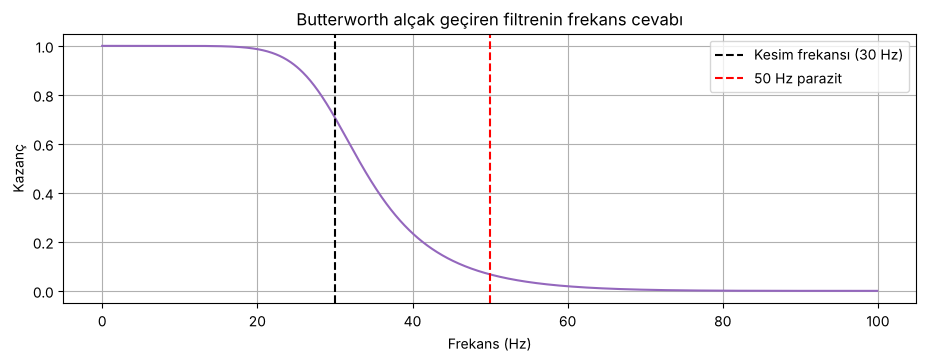

In [9]:
kesim_frekansi = 30   # Hz
derece = 4

# Butterworth alçak geçiren filtre katsayılarını hesapla
b, a = signal.butter(derece, kesim_frekansi, btype="low", fs=fs)

# Filtrenin frekans cevabını hesapla ve çiz
w, h = signal.freqz(b, a, worN=1024, fs=fs)
plt.plot(w, np.abs(h), color="tab:purple")
plt.axvline(kesim_frekansi, color="black", linestyle="--", label=f"Kesim frekansı ({kesim_frekansi} Hz)")
plt.axvline(50, color="red", linestyle="--", label="50 Hz parazit")
plt.title("Butterworth alçak geçiren filtrenin frekans cevabı")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Kazanç")
plt.legend()
plt.show()

### 3.2 Filtreyi sinyale uygulayalım
Şimdi ön işlenmiş sinyali filtreden geçiriyoruz ve sonucu hem **zaman** hem **frekans** domeninde karşılaştırıyoruz. Filtrelenmiş sinyalin çok daha "pürüzsüz" olduğunu ve spektrumdaki 50 Hz tepesinin kaybolduğunu göreceksiniz.

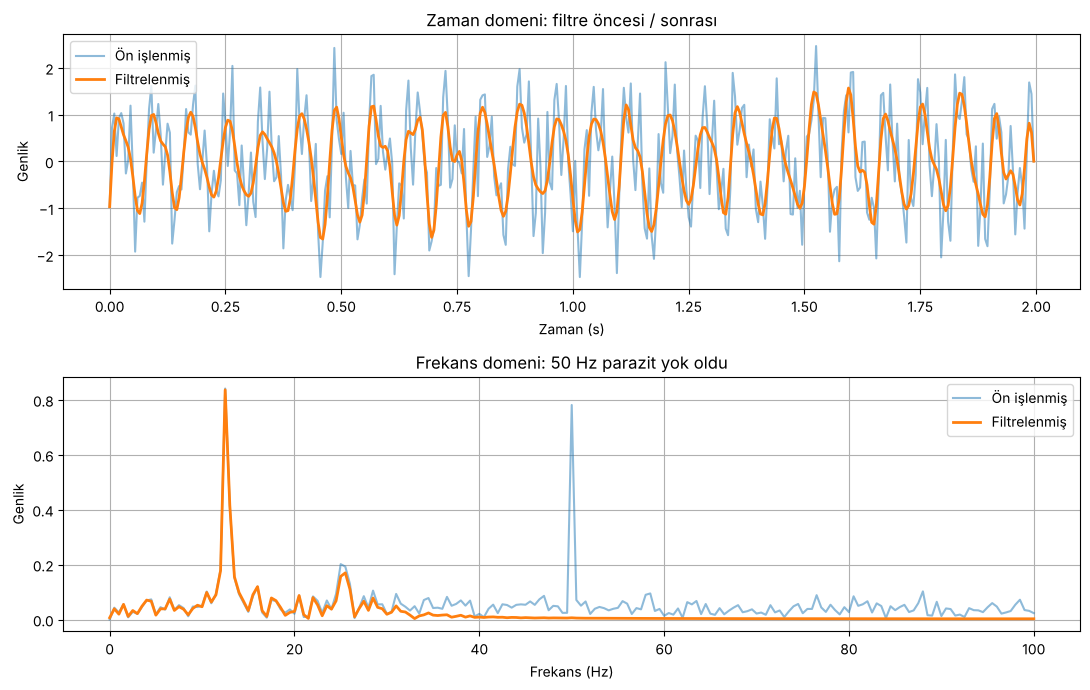

In [10]:
def filtrele(x):
    # Sinyale Butterworth alçak geçiren filtre uygular (faz kaymasız).
    return signal.filtfilt(b, a, x)

filtrelenmis = filtrele(on_islenmis)

fig, eksen = plt.subplots(2, 1, figsize=(11, 7))

# Üst grafik: Zaman domeni
eksen[0].plot(t, on_islenmis, color="tab:blue", alpha=0.5, label="Ön işlenmiş")
eksen[0].plot(t, filtrelenmis, color="tab:orange", linewidth=2, label="Filtrelenmiş")
eksen[0].set_title("Zaman domeni: filtre öncesi / sonrası")
eksen[0].set_xlabel("Zaman (s)"); eksen[0].set_ylabel("Genlik"); eksen[0].legend()

# Alt grafik: Frekans domeni
f1, g1 = spektrum_hesapla(on_islenmis, fs)
f2, g2 = spektrum_hesapla(filtrelenmis, fs)
eksen[1].plot(f1, g1, color="tab:blue", alpha=0.5, label="Ön işlenmiş")
eksen[1].plot(f2, g2, color="tab:orange", linewidth=2, label="Filtrelenmiş")
eksen[1].set_title("Frekans domeni: 50 Hz parazit yok oldu")
eksen[1].set_xlabel("Frekans (Hz)"); eksen[1].set_ylabel("Genlik"); eksen[1].legend()

plt.tight_layout()
plt.show()

### 3.3 Derinlemesine: Filtre neden faz kaymasına (gecikmeye) neden olur?

Bölüm 3.2'de `filtfilt` kullandık ve "faz kayması oluşturmaz" dedik. Peki faz kayması nedir ve neden oluşur?

#### Sezgi: Filtre geçmişe bakar
Gerçek zamanlı çalışan bir filtre (buna **nedensel / causal** filtre denir) bir çıkış değerini hesaplarken yalnızca **şimdiki ve geçmiş** giriş değerlerini kullanabilir; gelecekteki değerleri henüz bilmez.

Günlük hayattan bir örnek: Bugünün hava sıcaklığını **son 21 günün ortalaması** ile tahmin ettiğinizi düşünün. Mevsim ısınmaya başladığında bu ortalama gerçek sıcaklığın **gerisinde kalır**, çünkü içinde eski, soğuk günler de vardır. Ortalamanın "merkezi" aslında yaklaşık **10 gün öncesine** denk gelir.

Filtreler de aynı şekilde çalışır: Çıkış, girişin **geç kalmış (gecikmeli)** bir kopyası gibi davranır. Bu zaman gecikmesine, sinüs dalgaları açısından bakıldığında **faz kayması** denir.

Aşağıda bunu en basit filtre olan **hareketli ortalama** ile görelim. M noktalı nedensel hareketli ortalamanın gecikmesi şu formülle hesaplanır:

$$\text{gecikme} = \frac{M-1}{2} \ \text{örnek}$$

Beklenen gecikme: 10 örnek = 50 ms


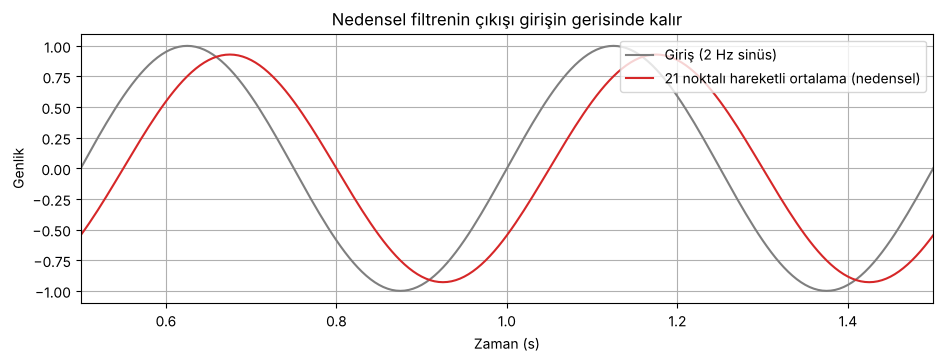

In [11]:
# 2 Hz'lik temiz bir sinüs (gürültüsüz, sadece gecikmeyi görmek için)
test_sinyali = np.sin(2*np.pi*2*t)

# Nedensel hareketli ortalama: her çıkış = şimdiki + önceki 20 değerin ortalaması
M = 21
hareketli_ort = signal.lfilter(np.ones(M)/M, 1, test_sinyali)

beklenen_gecikme = (M - 1) / 2   # örnek cinsinden
print(f"Beklenen gecikme: {beklenen_gecikme:.0f} örnek = {beklenen_gecikme/fs*1000:.0f} ms")

plt.plot(t, test_sinyali, color="tab:gray", label="Giriş (2 Hz sinüs)")
plt.plot(t, hareketli_ort, color="tab:red", label=f"{M} noktalı hareketli ortalama (nedensel)")
plt.xlim(0.5, 1.5)
plt.title("Nedensel filtrenin çıkışı girişin gerisinde kalır")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.legend(loc="upper right")
plt.show()

Kırmızı eğri gri eğrinin **sağa kaymış** (yani gecikmiş) hâli. Tepe noktaları yaklaşık 50 ms geç geliyor.

#### Butterworth filtremiz de gecikme yapar mı?
Evet. Bölüm 3.1'de tasarladığımız Butterworth filtresini `signal.lfilter` ile **tek yönlü** (sadece ileri) uygularsak, çıkış yine gecikir. Aynı filtreyi `filtfilt` ile uygularsak gecikme ortadan kalkar.

Aşağıda ön işlenmiş örnek sinyalimiz üzerinde iki yöntemi karşılaştırıyoruz. Gecikmeyi ölçmek için **çapraz korelasyon** kullanıyoruz: İki sinyali birbirine göre kaydırıp en iyi örtüştükleri kayma miktarını buluyoruz.

lfilter çıkışı, filtfilt çıkışına göre 3 örnek (= 15 ms) geride.


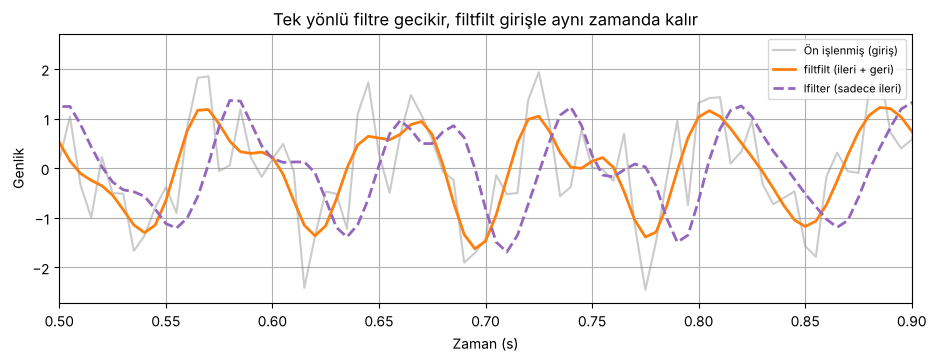

In [12]:
tek_yonlu = signal.lfilter(b, a, on_islenmis)    # Sadece ileri yönde filtre (gerçek zamanlı gibi)
cift_yonlu = signal.filtfilt(b, a, on_islenmis)  # İleri + geri (faz kaymasız)

# Çapraz korelasyon ile iki çıkış arasındaki gecikmeyi ölç
korelasyon = signal.correlate(tek_yonlu, cift_yonlu, mode="full")
kaymalar = signal.correlation_lags(len(tek_yonlu), len(cift_yonlu), mode="full")
olculen_gecikme = kaymalar[np.argmax(korelasyon)]
print(f"lfilter çıkışı, filtfilt çıkışına göre {olculen_gecikme} örnek "
      f"(= {olculen_gecikme/fs*1000:.0f} ms) geride.")

plt.plot(t, on_islenmis, color="tab:gray", alpha=0.4, label="Ön işlenmiş (giriş)")
plt.plot(t, cift_yonlu, color="tab:orange", linewidth=2, label="filtfilt (ileri + geri)")
plt.plot(t, tek_yonlu, color="tab:purple", linewidth=2, linestyle="--", label="lfilter (sadece ileri)")
plt.xlim(0.5, 0.9)
plt.title("Tek yönlü filtre gecikir, filtfilt girişle aynı zamanda kalır")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.legend(loc="upper right", fontsize=8)
plt.show()

#### Daha önemli sorun: Her frekans farklı miktarda gecikir
Hareketli ortalamada tüm frekanslar **aynı** miktarda gecikir; bu yüzden sinyalin şekli bozulmaz, sadece kayar. Butterworth gibi **IIR** filtrelerde ise gecikme **frekansa göre değişir**.

Bir frekans bileşeninin ne kadar geciktiğini **grup gecikmesi (group delay)** gösterir. Aşağıdaki grafikte filtremizin her frekansı kaç milisaniye geciktirdiğini görüyoruz.

Bunun anlamı şu: Sinyalimizde hem ana titreşim (örneğin 10 Hz) hem de harmoniği (20 Hz) var. Bu iki bileşen filtreden **farklı gecikmelerle** çıkarsa birbirlerine göre kayarlar ve **dalga şekli bozulur** (faz bozulması).

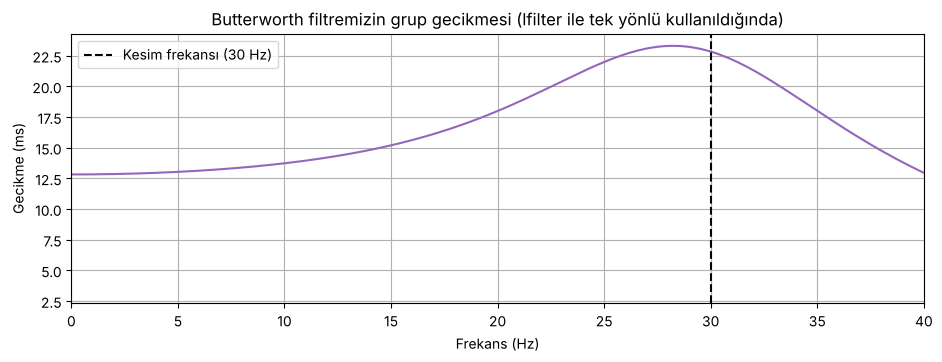

 5 Hz'lik bileşen ≈ 13.0 ms gecikir
10 Hz'lik bileşen ≈ 13.7 ms gecikir
20 Hz'lik bileşen ≈ 17.9 ms gecikir


In [13]:
frekanslar_gd, grup_gecikmesi = signal.group_delay((b, a), w=512, fs=fs)
grup_gecikmesi_ms = grup_gecikmesi / fs * 1000   # örnek → milisaniye

plt.plot(frekanslar_gd, grup_gecikmesi_ms, color="tab:purple")
plt.axvline(kesim_frekansi, color="black", linestyle="--", label=f"Kesim frekansı ({kesim_frekansi} Hz)")
plt.xlim(0, 40)
plt.title("Butterworth filtremizin grup gecikmesi (lfilter ile tek yönlü kullanıldığında)")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Gecikme (ms)")
plt.legend()
plt.show()

for f_ornek in [5, 10, 20]:
    indeks = np.argmin(np.abs(frekanslar_gd - f_ornek))
    print(f"{f_ornek:>2} Hz'lik bileşen ≈ {grup_gecikmesi_ms[indeks]:.1f} ms gecikir")

#### `filtfilt` bu sorunu nasıl çözer?
`filtfilt` dört basit adım uygular:

```
1. Sinyali filtrele (ileri yön)     → her frekans φ kadar gecikir
2. Sinyali ters çevir (sondan başa)
3. Tekrar filtrele                  → ters sinyalde gecikme, aslında ÖNE kaydırma demektir (−φ)
4. Sonucu tekrar ters çevir (düzelt)
```

Birinci geçişte oluşan gecikme, ikinci geçişte (ters yönde) **tam olarak geri alınır**: φ + (−φ) = 0. Bu yüzden `filtfilt`'e **sıfır fazlı (zero-phase) filtreleme** denir.

Bunu kendimiz de yazabiliriz. Aşağıda dört adımı elle uygulayıp `signal.filtfilt` ile karşılaştırıyoruz.

> Not: `scipy`'nin `filtfilt`'i sinyalin **kenarlarında** ek bir düzeltme (kenar uzatma) yapar. Bu yüzden iki sonucu kenarlardan uzakta, sinyalin orta kısmında karşılaştırıyoruz.

Orta bölgedeki en büyük fark: 0.000000  (pratikte sıfır → aynı sonuç)


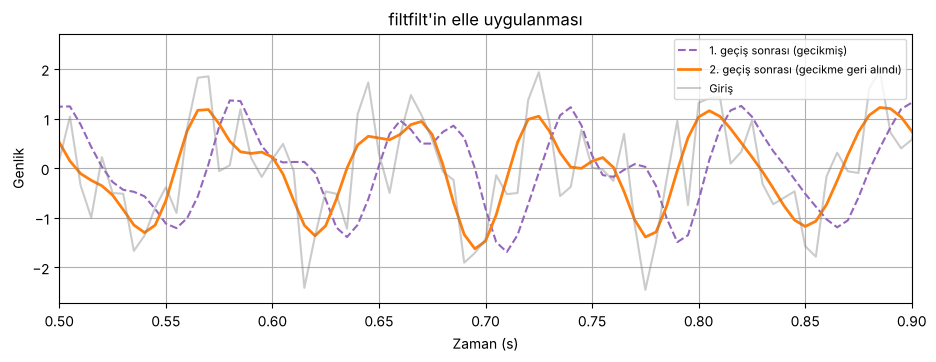

In [ ]:
# filtfilt'i manuel yazalım
adim1 = signal.lfilter(b, a, on_islenmis)   # 1) İleri yönde filtrele
adim2 = adim1[::-1]                          # 2) Ters çevir
adim3 = signal.lfilter(b, a, adim2)          # 3) Tekrar filtrele
elle_filtfilt = adim3[::-1]                  # 4) Tekrar ters çevir

orta = slice(50, -50)   # Kenarlardan 50'şer örnek uzak bölge
fark = np.max(np.abs(elle_filtfilt[orta] - cift_yonlu[orta]))
print(f"Orta bölgedeki en büyük fark: {fark:.6f}  (pratikte sıfır → aynı sonuç)")

plt.plot(t, adim1, color="tab:purple", linestyle="--", label="1. geçiş sonrası (gecikmiş)")
plt.plot(t, elle_filtfilt, color="tab:orange", linewidth=2, label="2. geçiş sonrası (gecikme geri alındı)")
plt.plot(t, on_islenmis, color="tab:gray", alpha=0.4, label="Giriş")
plt.xlim(0.5, 0.9)
plt.title("filtfilt'in elle uygulanması")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.legend(loc="upper right", fontsize=8)
plt.show()

#### `filtfilt`'in bir yan etkisi: Filtre iki kez uygulanır
Sinyal filtreden **iki kez** geçtiği için genlik cevabı da iki kez etki eder: Kazanç $|H(f)|$ yerine $|H(f)|^2$ olur.

- Geçirme bandında $|H| \approx 1$ olduğundan $1^2 = 1$ → **değişiklik yok**.
- Kesim frekansında $|H| = 0.707$ iken $0.707^2 = 0.5$ olur → kesim noktasında **daha fazla** zayıflatma.
- Durdurma bandında küçük değerler daha da küçülür → filtre **daha keskin** keser.

Yani `filtfilt` ile 4. derece bir filtre, kabaca **8. derece** bir filtre gibi davranır.

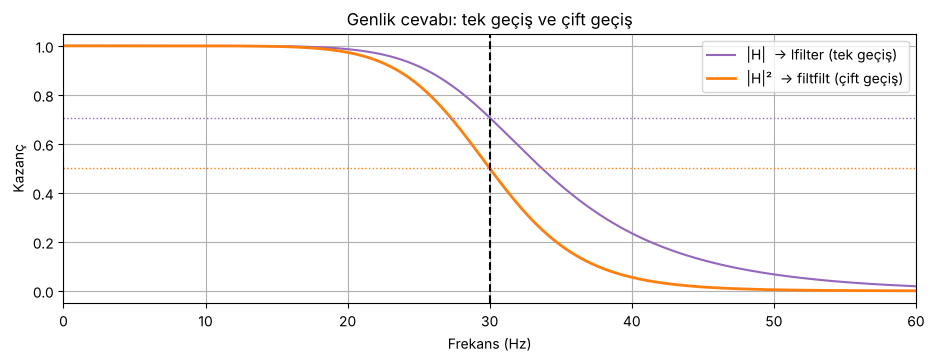

In [15]:
w, h = signal.freqz(b, a, worN=1024, fs=fs)

plt.plot(w, np.abs(h), color="tab:purple", label="|H|  → lfilter (tek geçiş)")
plt.plot(w, np.abs(h)**2, color="tab:orange", linewidth=2, label="|H|²  → filtfilt (çift geçiş)")
plt.axvline(kesim_frekansi, color="black", linestyle="--")
plt.axhline(0.707, color="tab:purple", linestyle=":", linewidth=1)
plt.axhline(0.5, color="tab:orange", linestyle=":", linewidth=1)
plt.xlim(0, 60)
plt.title("Genlik cevabı: tek geçiş ve çift geçiş")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Kazanç")
plt.legend()
plt.show()

#### Özet: Hangisini ne zaman kullanmalı?

| | `lfilter` (tek yönlü) | `filtfilt` (ileri + geri) |
|---|---|---|
| Faz kayması / gecikme | **Var**, frekansa göre değişebilir | **Yok** (sıfır fazlı) |
| Dalga şekli | Bozulabilir | Korunur |
| Gerçek zamanlı kullanılabilir mi? | ✅ Evet (sadece geçmişe bakar) | ❌ Hayır (sinyalin tamamı, yani "gelecek" de gerekir) |
| Genlik cevabı | $\lvert H \rvert$ | $\lvert H \rvert^2$ (daha keskin) |
| Tipik kullanım | Canlı sistemler: kalp pili, ses efekti, kontrol sistemleri | Kaydedilmiş verinin analizi: EKG/EEG analizi, laboratuvar ölçümleri |

**Bizim projemizde:** Kayıtların tamamı elimizde (her biri 2 saniye), yani gerçek zamanlı çalışmamız gerekmiyor. Bu yüzden `filtfilt` doğru tercih: Sinyalin şeklini ve zamanlamasını bozmadan gürültüyü temizliyor.

> **Önemli:** Gecikme her zaman sınıflandırmayı bozmaz. Bizim özniteliklerimiz (baskın frekans, sıfır geçiş sayısı vb.) sinyalin *ne zaman* olduğuna değil, *nasıl salındığına* bakar. Ama örneğin EKG'de kalp atışının **tam zamanını** bulmak istiyorsanız birkaç milisaniyelik gecikme bile ölçümü yanlış yapar.

## 4. Veri Setini Oluşturma

Tek bir sinyalle model eğitemeyiz; **çok sayıda örneğe** ihtiyacımız var. Her sınıftan 100 kayıt, toplam **300 sinyal** üretiyoruz.

Her sinyal aynı boru hattından (pipeline) geçiyor:

```
ham sinyal → on_isleme() → filtrele() → temiz sinyal
```

- `X_sinyaller` → Temiz sinyaller (300 satır × 400 sütun)
- `y` → Her sinyalin doğru sınıf etiketi (0, 1 veya 2)

In [16]:
ornek_sayisi_sinif_basina = 100

X_sinyaller = []   # Temizlenmiş sinyaller
y = []             # Etiketler

for sinif in [0, 1, 2]:
    for _ in range(ornek_sayisi_sinif_basina):
        ham, _ = sinyal_uret(sinif)
        temiz = filtrele(on_isleme(ham))
        X_sinyaller.append(temiz)
        y.append(sinif)

X_sinyaller = np.array(X_sinyaller)
y = np.array(y)

print("Sinyal matrisinin boyutu:", X_sinyaller.shape, " → (sinyal sayısı, örnek sayısı)")
print("Etiket sayıları         :", np.bincount(y), " → her sınıftan kaç örnek var")

Sinyal matrisinin boyutu: (300, 400)  → (sinyal sayısı, örnek sayısı)
Etiket sayıları         : [100 100 100]  → her sınıftan kaç örnek var


Her sınıftan birer temiz sinyal çizerek sınıflar arasındaki farkı gözle görelim. Yüksek hız sınıfında dalgaların **daha sık** olduğuna dikkat edin.

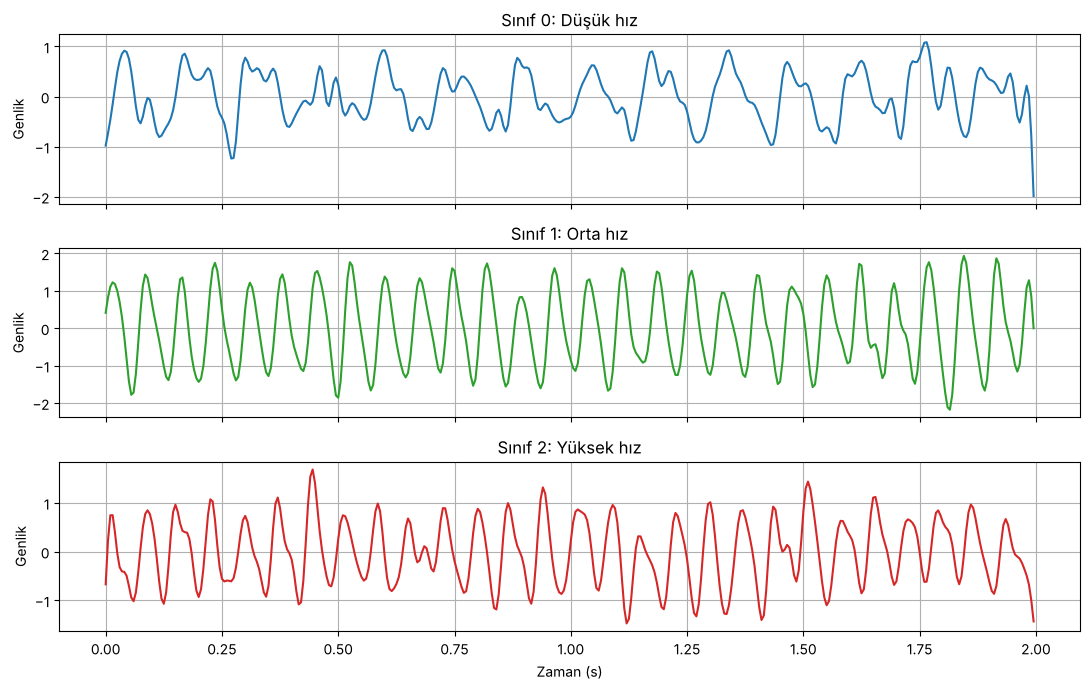

In [17]:
fig, eksen = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
renkler = ["tab:blue", "tab:green", "tab:red"]

for sinif in [0, 1, 2]:
    indeks = np.where(y == sinif)[0][0]      # Bu sınıfın ilk örneği
    eksen[sinif].plot(t, X_sinyaller[indeks], color=renkler[sinif])
    eksen[sinif].set_title(f"Sınıf {sinif}: {sinif_adlari[sinif]}")
    eksen[sinif].set_ylabel("Genlik")

eksen[2].set_xlabel("Zaman (s)")
plt.tight_layout()
plt.show()

## 5. Öznitelik Çıkarma (Feature Extraction)

Bir sınıflandırıcıya 400 sayılık ham sinyali vermek yerine, sinyali **birkaç anlamlı sayıyla özetleriz**. Bu sayılara **öznitelik (feature)** denir. Bir insanı "boy, kilo, yaş" ile özetlemek gibi düşünebilirsiniz.

Kullanacağımız öznitelikler:

| Öznitelik | Domen | Ne anlatır? |
|---|---|---|
| **RMS** (Karesel ortalamanın karekökü) | Zaman | Sinyalin ortalama "gücü / şiddeti" |
| **Tepeden tepeye (Peak-to-Peak)** | Zaman | En büyük ve en küçük değer arasındaki fark |
| **Standart sapma** | Zaman | Değerlerin ortalama etrafında ne kadar yayıldığı |
| **Sıfır geçiş sayısı (ZCR)** | Zaman | Sinyal kaç kez sıfır çizgisini kesiyor? Hızlı salınan sinyal daha çok keser |
| **Baskın frekans** | Frekans | Spektrumdaki en yüksek tepenin frekansı |
| **Spektral merkez (centroid)** | Frekans | Spektrumun "ağırlık merkezi" — enerjinin ortalama frekansı |

---

> İpucu: Genlikleri bilerek her sınıfta **aynı aralıkta** ürettik. Bu yüzden RMS gibi genlik tabanlı özniteliklerin sınıfları ayırmada pek işe yaramamasını bekliyoruz. Bunu Bölüm 5.2'de kontrol edeceğiz!

In [18]:
def oznitelik_cikar(x, fs):
    # Tek bir sinyalden 6 sayısal öznitelik hesaplar ve sözlük olarak döndürür.
    # --- Zaman domeni öznitelikleri ---
    rms = np.sqrt(np.mean(x**2))
    tepe_tepe = np.max(x) - np.min(x)
    std = np.std(x)
    sifir_gecis = np.sum(np.diff(np.sign(x)) != 0)   # İşaret değişimlerini say

    # --- Frekans domeni öznitelikleri ---
    frek, genlik = spektrum_hesapla(x, fs)
    baskin_frekans = frek[np.argmax(genlik)]
    spektral_merkez = np.sum(frek * genlik) / np.sum(genlik)

    return {
        "RMS": rms,
        "Tepe_Tepe": tepe_tepe,
        "Std": std,
        "Sifir_Gecis": sifir_gecis,
        "Baskin_Frekans": baskin_frekans,
        "Spektral_Merkez": spektral_merkez,
    }

# Tüm sinyaller için öznitelikleri hesaplayıp bir tabloya (DataFrame) koyalım
oznitelik_listesi = [oznitelik_cikar(x, fs) for x in X_sinyaller]
df = pd.DataFrame(oznitelik_listesi)
df["Sinif"] = y

print("Öznitelik tablosunun boyutu:", df.shape)
df.head(10)

Öznitelik tablosunun boyutu: (300, 7)


,RMS,Tepe_Tepe,Std,Sifir_Gecis,Baskin_Frekans,Spektral_Merkez,Sinif
0,0.508481,3.072742,0.508476,34,7.0,22.454530,0
1,0.794539,3.568020,0.794537,23,5.5,18.884737,0
2,1.115041,4.236416,1.115041,36,8.5,13.555196,0
3,1.029360,3.673125,1.029359,19,4.5,15.035980,0
4,1.126347,4.634852,1.126341,24,6.0,13.491254,0
5,0.555275,2.293586,0.555267,24,4.0,13.119510,0
6,1.106025,4.407668,1.106025,26,6.5,13.647463,0
7,1.136195,5.298777,1.136193,17,3.5,21.780350,0
8,1.052621,4.204251,1.052616,25,5.5,17.755080,0
9,0.457711,2.030522,0.457703,34,6.0,16.908670,0


### 5.1 Sınıflara göre ortalama değerler
`groupby` ile her sınıfın öznitelik ortalamalarını görelim. Sınıflar arasında **büyük fark olan** öznitelikler, ayırt edici olmaya adaydır.

In [19]:
df.groupby("Sinif").mean().round(2)

,RMS,Tepe_Tepe,Std,Sifir_Gecis,Baskin_Frekans,Spektral_Merkez
Sinif,,,,,,
0,0.81,3.37,0.81,29.17,5.71,16.90
1,0.77,3.32,0.77,45.14,10.82,19.91
2,0.78,3.32,0.78,66.62,16.62,22.00


### 5.2 Öznitelikleri görselleştirme (kutu grafikleri)
**Kutu grafiği (boxplot)** her sınıftaki değerlerin dağılımını gösterir. Bir öznitelikte kutular birbirinden **ayrık** ise o öznitelik sınıfları iyi ayırıyor demektir. Kutular **üst üste** ise o öznitelik pek bilgi taşımıyordur.

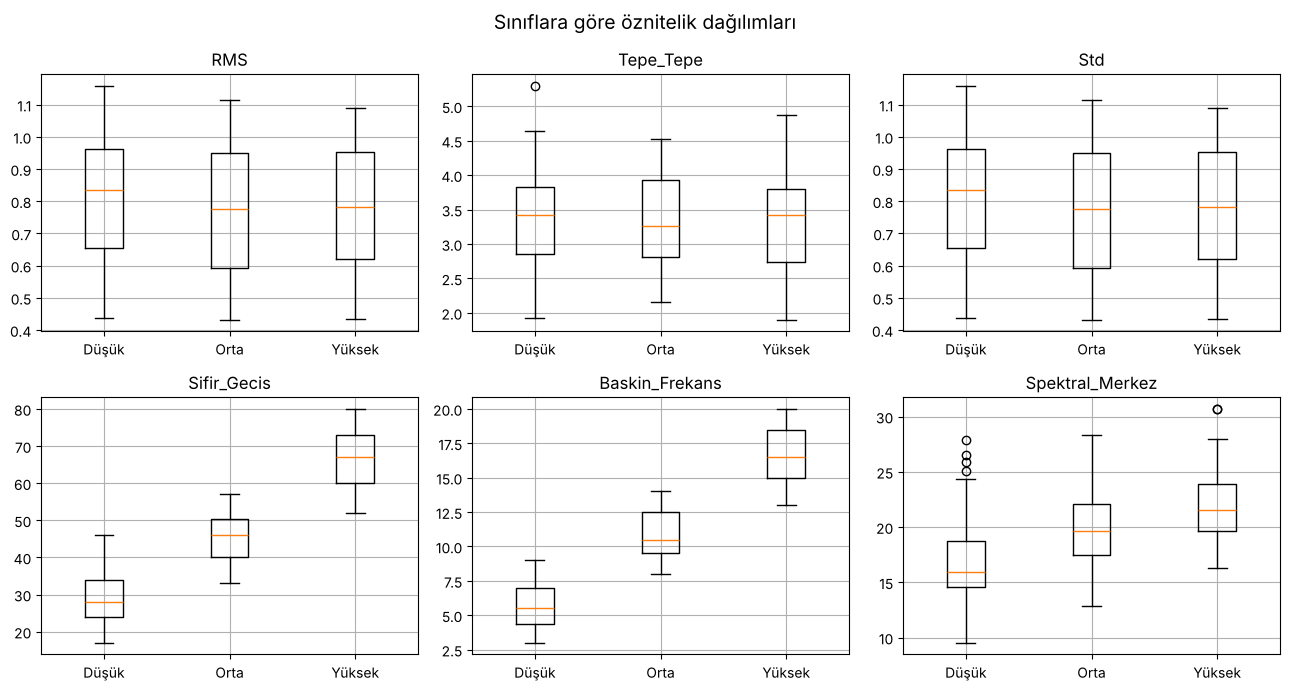

In [20]:
oznitelik_adlari = ["RMS", "Tepe_Tepe", "Std", "Sifir_Gecis", "Baskin_Frekans", "Spektral_Merkez"]

fig, eksen = plt.subplots(2, 3, figsize=(13, 7))
for ax, ad in zip(eksen.ravel(), oznitelik_adlari):
    veriler = [df[df["Sinif"] == s][ad] for s in [0, 1, 2]]
    ax.boxplot(veriler)
    ax.set_xticklabels(["Düşük", "Orta", "Yüksek"])
    ax.set_title(ad)

plt.suptitle("Sınıflara göre öznitelik dağılımları", fontsize=14)
plt.tight_layout()
plt.show()

**Ne görüyoruz?**
- **RMS, Tepe_Tepe ve Std:** Kutular büyük ölçüde üst üste → Bu öznitelikler sınıfları **ayırmıyor** (beklediğimiz gibi, çünkü genlikler her sınıfta benzer).
- **Sifir_Gecis ve Baskin_Frekans:** Kutular belirgin şekilde ayrık → Bunlar **çok bilgilendirici**. Zaten sınıfları belirleyen şey frekanstı!
- **Spektral_Merkez:** Sınıf hızlandıkça artıyor ama kutular kısmen örtüşüyor. Çünkü filtreden sonra 30 Hz'e kadar olan gürültü hâlâ sinyalde ve spektrumun "ağırlık merkezini" yukarı çekiyor. Yani **orta derecede** bilgilendirici.
- Düşük–Orta ve Orta–Yüksek kutularının uçları biraz **örtüşüyor**. Çünkü frekans aralıklarını bilerek çakışık seçtik (8–9 Hz ve 13–14 Hz). Bu bölgelerdeki örneklerde modelin hata yapmasını bekleyebiliriz.

## 6. Eğitim ve Test Setlerine Ayırma

Modelin başarısını **adil** ölçmek için veriyi ikiye ayırırız:

- **Eğitim seti (%70):** Model bu verilerden öğrenir.
- **Test seti (%30):** Model bu verileri eğitim sırasında **hiç görmez**. Sonunda bunlarla sınav yapılır.

Bir öğrenciye çalışırken gösterdiğimiz soruları sınavda sormamak gibi düşünebilirsiniz; aksi hâlde gerçekten öğrenip öğrenmediğini anlayamayız.

- `stratify=y` → Her iki sette de sınıf oranlarının aynı kalmasını sağlar.
- `random_state=42` → Ayırma işlemi her çalıştırmada aynı olur.

In [21]:
X = df[oznitelik_adlari].values   # Öznitelik matrisi (300 × 6)
etiketler = df["Sinif"].values     # Etiketler

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, etiketler, test_size=0.30, random_state=42, stratify=etiketler
)

print(f"Eğitim seti: {X_egitim.shape[0]} örnek  | sınıf dağılımı: {np.bincount(y_egitim)}")
print(f"Test seti  : {X_test.shape[0]} örnek  | sınıf dağılımı: {np.bincount(y_test)}")

Eğitim seti: 210 örnek  | sınıf dağılımı: [70 70 70]
Test seti  : 90 örnek  | sınıf dağılımı: [30 30 30]


### 6.1 Öznitelik ölçekleme (Standardizasyon)
Özniteliklerimizin birimleri ve büyüklükleri çok farklı: `Sifir_Gecis` 10–80 arası, `RMS` ise 0.3–1.2 arası. Mesafeye dayalı modeller (k-NN gibi) büyük sayılı özniteliklere **haksız şekilde daha fazla önem verir**.

`StandardScaler` her özniteliği **ortalaması 0, standart sapması 1** olacak şekilde dönüştürür:

$$z = \frac{x - \mu}{\sigma}$$

⚠️ **Önemli kural:** Ölçekleyici (`fit`) **sadece eğitim verisiyle** öğrenilir; test verisine aynı dönüşüm (`transform`) uygulanır. Test verisinden bilgi sızarsa sonuçlarımız olduğundan iyi görünür (buna *veri sızıntısı* denir).

In [22]:
olcekleyici = StandardScaler()
X_egitim_olcekli = olcekleyici.fit_transform(X_egitim)   # Eğitimden öğren + dönüştür
X_test_olcekli = olcekleyici.transform(X_test)           # Sadece dönüştür

print("Ölçekleme sonrası eğitim verisi ortalamaları:", X_egitim_olcekli.mean(axis=0).round(2))
print("Ölçekleme sonrası eğitim verisi std değerleri:", X_egitim_olcekli.std(axis=0).round(2))

Ölçekleme sonrası eğitim verisi ortalamaları: [-0.  0. -0.  0.  0.  0.]
Ölçekleme sonrası eğitim verisi std değerleri: [1. 1. 1. 1. 1. 1.]


## 7. Sınıflandırma: k-En Yakın Komşu (k-NN)

**k-NN** en sezgisel sınıflandırıcılardan biridir:

1. Sınıfını bilmediğimiz yeni bir örnek gelir.
2. Model, eğitim setinde bu örneğe **en yakın k tane** örneği bulur (öznitelik uzayında mesafe ölçerek).
3. Bu k komşu arasında **en çok hangi sınıf varsa**, yeni örneğe o sınıfı verir (oylama).

Biz `k = 5` seçiyoruz.

- `fit()` → Modeli eğitim verisiyle eğitir (k-NN için bu, aslında eğitim örneklerini hafızaya almaktır).
- `predict()` → Test örneklerinin sınıfını tahmin eder.

In [23]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_egitim_olcekli, y_egitim)          # Eğitim

y_tahmin = model.predict(X_test_olcekli)       # Test verisi üzerinde tahmin

# İlk 15 test örneği için gerçek ve tahmin edilen sınıfları yan yana gösterelim
karsilastirma = pd.DataFrame({"Gerçek": y_test[:15], "Tahmin": y_tahmin[:15]})
karsilastirma["Doğru mu?"] = np.where(karsilastirma["Gerçek"] == karsilastirma["Tahmin"], "✓", "✗")
karsilastirma.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Gerçek,0,0,2,1,0,0,1,1,0,1,1,1,2,2,2
Tahmin,0,1,2,1,0,0,1,1,0,1,1,1,2,1,2
Doğru mu?,✓,✗,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✗,✓


## 8. Sonuçları Değerlendirme ve Yorumlama

### 8.1 Doğruluk (Accuracy)
En basit ölçüt: **Doğru tahmin sayısı / Toplam tahmin sayısı.**

Ayrıca eğitim doğruluğunu da hesaplıyoruz. Eğitim ve test doğrulukları birbirine yakınsa model **genelleme** yapabiliyor demektir. Eğitim çok yüksek ama test çok düşükse model ezberlemiş (**aşırı öğrenme / overfitting**) olabilir.

In [24]:
egitim_dogrulugu = accuracy_score(y_egitim, model.predict(X_egitim_olcekli))
test_dogrulugu = accuracy_score(y_test, y_tahmin)

print(f"Eğitim doğruluğu: %{egitim_dogrulugu*100:.1f}")
print(f"Test doğruluğu  : %{test_dogrulugu*100:.1f}")
print(f"Test setinde {len(y_test)} örnekten {np.sum(y_test == y_tahmin)} tanesi doğru, "
      f"{np.sum(y_test != y_tahmin)} tanesi yanlış tahmin edildi.")

Eğitim doğruluğu: %89.0
Test doğruluğu  : %88.9
Test setinde 90 örnekten 80 tanesi doğru, 10 tanesi yanlış tahmin edildi.


### 8.2 Karışıklık Matrisi (Confusion Matrix)
Doğruluk tek bir sayıdır; **hangi sınıfların karıştırıldığını** söylemez. Karışıklık matrisi bunu gösterir:

- **Satırlar:** Gerçek sınıf
- **Sütunlar:** Modelin tahmini
- **Köşegen (sol üstten sağ alta):** Doğru tahminler ✅
- **Köşegen dışı:** Hatalar ❌ — örneğin "Gerçek: Orta, Tahmin: Yüksek" hücresi, orta hızdaki motorun kaç kez yanlışlıkla yüksek hız sanıldığını gösterir.

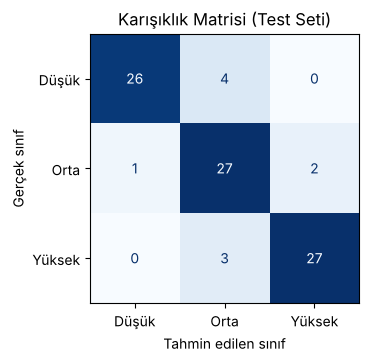

In [25]:
cm = confusion_matrix(y_test, y_tahmin)
gosterim = ConfusionMatrixDisplay(cm, display_labels=["Düşük", "Orta", "Yüksek"])
gosterim.plot(cmap="Blues", colorbar=False)
plt.title("Karışıklık Matrisi (Test Seti)")
plt.xlabel("Tahmin edilen sınıf")
plt.ylabel("Gerçek sınıf")
plt.grid(False)
plt.show()

### 8.3 Sınıflandırma Raporu
Her sınıf için üç ölçüt verir:

- **Precision (Kesinlik):** Model "bu Yüksek hız" dediğinde ne kadar haklı? → *Doğru Yüksek tahminleri / Tüm Yüksek tahminleri*
- **Recall (Duyarlılık):** Gerçek Yüksek hız örneklerinin ne kadarını yakalayabildi? → *Doğru Yüksek tahminleri / Gerçek Yüksek örnek sayısı*
- **F1-skoru:** Precision ve Recall'un dengeli ortalaması (harmonik ortalama).
- **support:** Test setinde o sınıftan kaç örnek olduğu.


Precision = TP / (TP + FP)
Recall = = TP / (TP + FN)
F1 = 2 * (Precision * Recall) / (Precision + Recall)

In [26]:
print(classification_report(y_test, y_tahmin, target_names=["Düşük hız", "Orta hız", "Yüksek hız"], digits=3))

              precision    recall  f1-score   support

   Düşük hız      0.963     0.867     0.912        30
    Orta hız      0.794     0.900     0.844        30
  Yüksek hız      0.931     0.900     0.915        30

    accuracy                          0.889        90
   macro avg      0.896     0.889     0.890        90
weighted avg      0.896     0.889     0.890        90



### 8.4 Yanlış sınıflandırılan örnekleri inceleyelim
Modelin **neden** hata yaptığını anlamak, sonucun en öğretici kısmıdır. Hatalı tahmin edilen test örneklerinin baskın frekanslarına bakalım. Hatırlayın, sınıf aralıkları **8–9 Hz** ve **13–14 Hz** bölgelerinde çakışıyordu.

,Gerçek sınıf,Tahmin,Baskın frekans (Hz)
0,Düşük hız,Orta hız,7.0
1,Yüksek hız,Orta hız,13.0
2,Düşük hız,Orta hız,8.5
3,Düşük hız,Orta hız,8.0
4,Düşük hız,Orta hız,8.5
5,Orta hız,Düşük hız,8.0
6,Orta hız,Yüksek hız,14.0
7,Yüksek hız,Orta hız,14.0
8,Orta hız,Yüksek hız,13.5
9,Yüksek hız,Orta hız,14.0


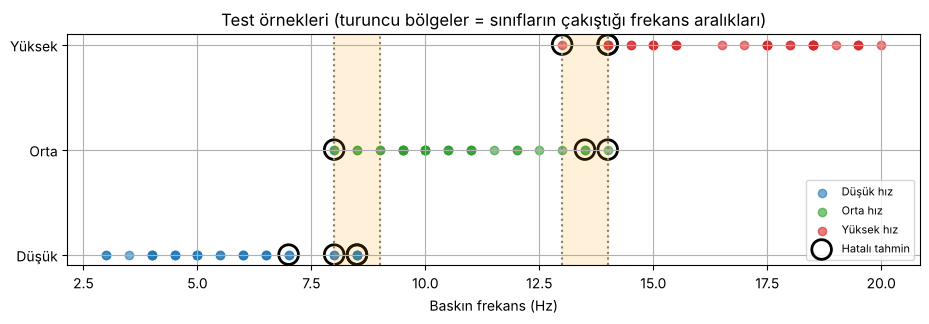

In [27]:
hatali = np.where(y_test != y_tahmin)[0]

if len(hatali) == 0:
    print("Test setinde hiç hata yok!")
else:
    hata_tablosu = pd.DataFrame({
        "Gerçek sınıf": [sinif_adlari[s] for s in y_test[hatali]],
        "Tahmin": [sinif_adlari[s] for s in y_tahmin[hatali]],
        "Baskın frekans (Hz)": X_test[hatali, oznitelik_adlari.index("Baskin_Frekans")],
    })
    display(hata_tablosu)

# Tüm test örneklerini baskın frekansa göre çiz; hataları işaretle
bf = X_test[:, oznitelik_adlari.index("Baskin_Frekans")]
plt.figure(figsize=(11, 3))
for s, renk in zip([0, 1, 2], renkler):
    m = y_test == s
    plt.scatter(bf[m], np.full(m.sum(), s), color=renk, alpha=0.6, label=sinif_adlari[s])
plt.scatter(bf[hatali], y_test[hatali], facecolors="none", edgecolors="black", s=200, linewidths=2, label="Hatalı tahmin")
for sinir in [8, 9, 13, 14]:
    plt.axvline(sinir, color="gray", linestyle=":")
plt.axvspan(8, 9, color="orange", alpha=0.15)
plt.axvspan(13, 14, color="orange", alpha=0.15)
plt.yticks([0, 1, 2], ["Düşük", "Orta", "Yüksek"])
plt.xlabel("Baskın frekans (Hz)")
plt.title("Test örnekleri (turuncu bölgeler = sınıfların çakıştığı frekans aralıkları)")
plt.legend(loc="lower right", fontsize=8)
plt.show()

### 8.5 Genel Yorum

1. **Ön işleme ve filtreleme işe yaradı.** Detrend ile DC ofset ve kayma, alçak geçiren filtre ile 50 Hz parazit ve yüksek frekanslı gürültü temizlendi. Temiz sinyalden çıkarılan öznitelikler daha güvenilir oldu.

2. **Doğru öznitelik seçimi başarının anahtarıdır.** Sınıfları belirleyen fiziksel büyüklük *frekans* olduğu için `Baskin_Frekans` ve `Sifir_Gecis` öznitelikleri sınıfları çok iyi ayırdı. Genliğe dayalı RMS / Std / Tepe_Tepe ise neredeyse hiç katkı sağlamadı; hatta k-NN mesafe hesabına "gürültü" eklediği için başarıyı biraz **düşürebilir** (Alıştırma 5'te deneyin). **Sinyali tanımak = doğru özniteliği seçmek.**

3. **Hatalar rastgele değil, açıklanabilir.** Karışıklık matrisinde hatalar yalnızca **komşu sınıflar** arasında (Düşük↔Orta, Orta↔Yüksek). Düşük hız hiçbir zaman Yüksek hız ile karıştırılmadı. Hatalı örneklerin baskın frekansları da çoğunlukla sınıf aralıklarının **çakıştığı bölgelerde ya da hemen yanında** (8–9 Hz, 13–14 Hz). Ayrıca FFT'nin frekans çözünürlüğü `fs / N = 0.5 Hz` olduğundan baskın frekans en yakın 0.5 Hz'e yuvarlanıyor; bu da sınır bölgesindeki örnekleri daha belirsiz yapıyor. Yani bu örneklerde bir insan uzman da kararsız kalırdı; problem verinin doğasından kaynaklanıyor.

4. **Model ezberlemedi.** Eğitim ve test doğrulukları birbirine yakın olduğu için model daha önce görmediği verilerde de benzer başarı gösteriyor.

## 9. Alıştırmalar

Öğrendiklerinizi pekiştirmek için aşağıdaki değişiklikleri yapıp notebook'u yeniden çalıştırın ve sonuçların nasıl değiştiğini gözlemleyin:

1. **Gürültüyü artırın:** `sinyal_uret` içindeki `0.5 * rng.standard_normal(N)` ifadesini `2.0 * ...` yapın. Doğruluk ne oldu?
2. **Filtreyi kaldırın:** Bölüm 4'teki döngüde `temiz = filtrele(on_isleme(ham))` yerine `temiz = ham` yazın. Hangi öznitelikler bozuldu? (İpucu: `Sifir_Gecis` ve `Spektral_Merkez`'e bakın.)
3. **Kesim frekansını değiştirin:** `kesim_frekansi = 10` yapın. Yüksek hız sınıfına ne oldu? Neden?
4. **Sadece genlik öznitelikleriyle deneyin:** Bölüm 6'daki `X = df[oznitelik_adlari].values` satırını `X = df[["RMS", "Tepe_Tepe", "Std"]].values` yapın. Doğruluk ne olur? (Rastgele tahmin ≈ %33)
5. **Sadece frekans öznitelikleriyle deneyin:** Aynı satırı `X = df[["Baskin_Frekans", "Sifir_Gecis"]].values` yapın. Gereksiz öznitelikleri çıkarmak başarıyı artırdı mı?
6. **k değerini değiştirin:** `n_neighbors` değerini 1, 3, 15 yapın. (Not: Gerçek projelerde k gibi ayarlar test setine bakarak değil, ayrı bir *doğrulama seti* veya *çapraz doğrulama* ile seçilir.)
7. **Başka bir sınıflandırıcı deneyin:** `from sklearn.tree import DecisionTreeClassifier` ile karar ağacı kullanıp sonuçları k-NN ile karşılaştırın.
8. **filtfilt yerine lfilter kullanın:** `filtrele` fonksiyonunda `signal.filtfilt(b, a, x)` yerine `signal.lfilter(b, a, x)` yazın. Sınıflandırma doğruluğu çok değişti mi? Neden?